In [ ]:
from sklearn.model_selection import train_test_split
from qiskit_machine_learning.utils import algorithm_globals
from qiskit.circuit.library import zz_feature_map
from qiskit.circuit.library import real_amplitudes
from qiskit_machine_learning.optimizers import COBYLA
from qiskit.primitives import StatevectorSampler as Sampler

import time
from qiskit_machine_learning.algorithms.classifiers import VQC
from qiskit.circuit.library import efficient_su2

algorithm_globals.random_seed = 42

In [2]:
import pandas as pd
import numpy as np

train_df = pd.read_csv('train_data.csv')
test_df = pd.read_csv('test_data.csv')

X_train = train_df.drop('label', axis=1).values
y_train = train_df['label'].values
X_test = test_df.drop('label', axis=1).values
y_test = test_df['label'].values

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train labels: {np.unique(y_train, return_counts=True)}")
print(f"Test labels: {np.unique(y_test, return_counts=True)}")

Train: (38, 7129), Test: (34, 7129)
Train labels: (array([0, 1]), array([27, 11]))
Test labels: (array([0, 1]), array([20, 14]))


In [3]:
from matplotlib import pyplot as plt
from IPython.display import clear_output
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA
from qiskit.transpiler import generate_preset_pass_manager

objective_func_vals = []
plt.rcParams["figure.figsize"] = (12, 6)

all_results = []

def callback_graph(weights, obj_func_eval):
    clear_output(wait=True)
    objective_func_vals.append(obj_func_eval)
    plt.title("Objective function value against iteration")
    plt.xlabel("Iteration")
    plt.ylabel("Objective function value")
    plt.plot(range(len(objective_func_vals)), objective_func_vals)
    plt.show()


def run_vqc(optimizer, sampler, pca_value, feature_map, ansatz,
            X_train, y_train, X_test, y_test,
            backend=None, pass_manager=None):
    """
    Train and evaluate a VQC model.

    Returns: dict with train_acc, test_acc, train_time, num_params,
             circuit_depth, pca_var, num_qubits, vqc
    """
    global objective_func_vals

    # PCA
    if pca_value is not None:
        pca = PCA(n_components=pca_value)
        X_tr = pca.fit_transform(X_train)
        X_te = pca.transform(X_test)
        pca_var = round(pca.explained_variance_ratio_.sum(), 4)
    else:
        X_tr, X_te = X_train, X_test
        pca_var = 'N/A'

    num_qubits = X_tr.shape[1]

    # Circuit depth
    full_circuit = feature_map.compose(ansatz)
    circuit_depth = full_circuit.decompose().depth()

    # Build VQC
    vqc_kwargs = dict(
        sampler=sampler,
        feature_map=feature_map,
        ansatz=ansatz,
        optimizer=optimizer,
        callback=callback_graph,
    )
    if pass_manager is not None:
        vqc_kwargs['pass_manager'] = pass_manager

    vqc = VQC(**vqc_kwargs)

    # Train
    objective_func_vals = []
    start = time.time()
    vqc.fit(X_tr, y_train)
    elapsed = time.time() - start

    # Score
    train_acc = vqc.score(X_tr, y_train)
    test_acc = vqc.score(X_te, y_test)

    num_params = ansatz.num_parameters + feature_map.num_parameters

    print(f"Params: {num_params} | Depth: {circuit_depth} | Time: {elapsed:.2f}s | Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

    return {
        'vqc': vqc,
        'num_params': num_params,
        'circuit_depth': circuit_depth,
        'pca_var': pca_var,
        'num_qubits': num_qubits,
        'train_time': round(elapsed, 4),
        'train_acc': round(train_acc, 4),
        'test_acc': round(test_acc, 4),
    }


def log_result(r, model_name, **extra):
    """
    Append a result to all_results.

    Args:
        r:          dict returned by run_vqc
        model_name: string describing the model
        **extra:    any additional columns to include/override
    """
    full_name = f"{model_name} | qubits:{r['num_qubits']} | depth:{r['circuit_depth']}"
    entry = {
        'Model': full_name,
        'Num Features': r['num_qubits'],
        'PCA Variance': r['pca_var'],
        'Parameters': r['num_params'],
        'Train Time (s)': r['train_time'],
        'Train Accuracy': r['train_acc'],
        'Test Accuracy': r['test_acc'],
    }
    entry.update(extra)
    all_results.append(entry)
    print(f"Logged: {full_name}")

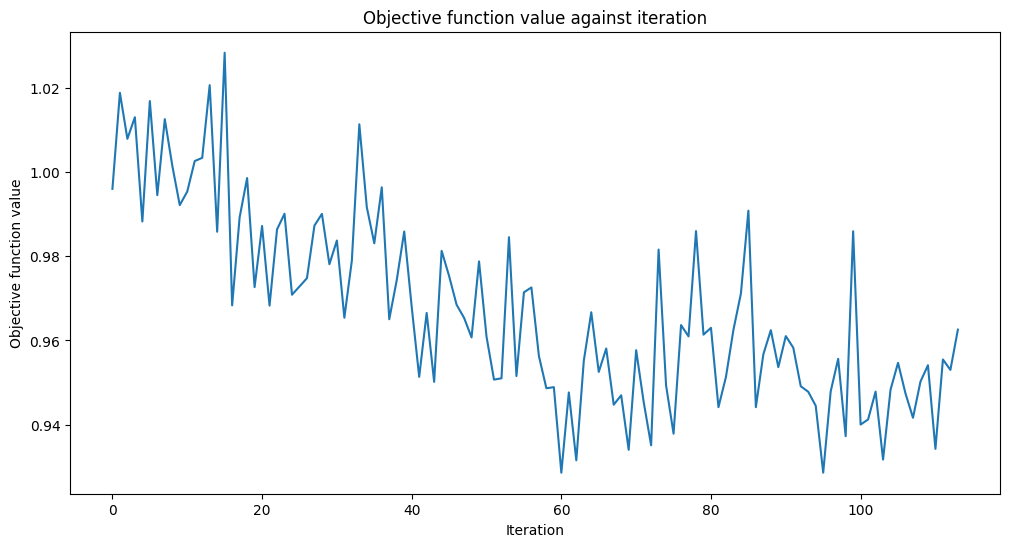

Params: 119 | Depth: 69 | Time: 36.47s | Train Acc: 0.7368 | Test Acc: 0.5000
Logged: VQC | backend:statevector(Ideal) | opt:COBYLA(maxiter=100) | fm:ZZFeatureMap(reps=1) | ans:EfficientSU2(reps=7) | qubits:7 | depth:69


In [4]:
## Ideal Statevector VQC — sweep ansatz reps 1-7
for reps in range(1, 8):
    fm = zz_feature_map(feature_dimension=7, reps=1)
    ans = efficient_su2(num_qubits=7, reps=reps)

    r = run_vqc(
        optimizer=COBYLA(maxiter=100),
        sampler=Sampler(),
        pca_value=0.5,
        feature_map=fm, ansatz=ans,
        X_train=X_train, y_train=y_train,
        X_test=X_test, y_test=y_test,
    )

    log_result(r, f"VQC | backend:statevector(Ideal) | opt:COBYLA(maxiter=100) | fm:ZZFeatureMap(reps=1) | ans:EfficientSU2(reps={reps})")

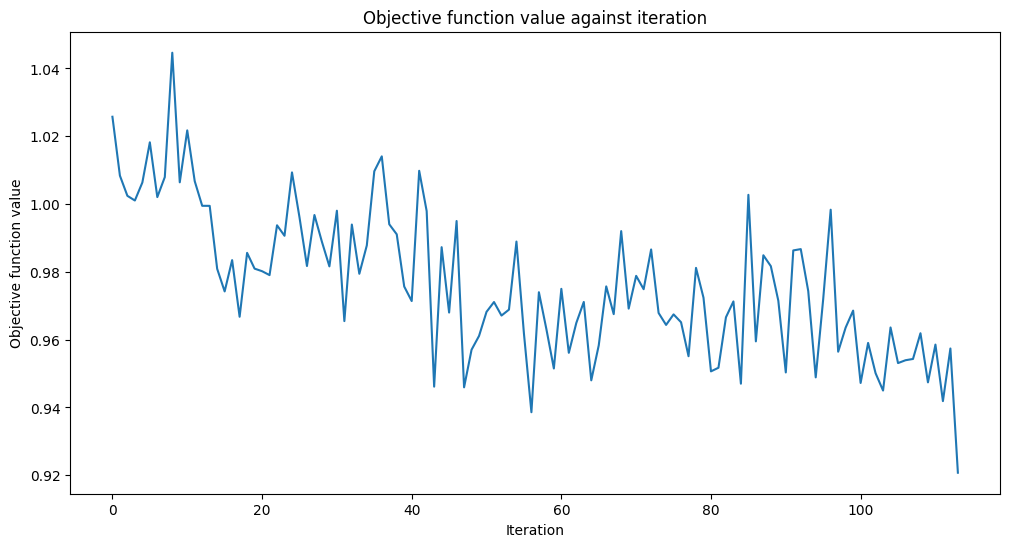

Params: 119 | Depth: 69 | Time: 69.56s | Train Acc: 0.7368 | Test Acc: 0.5294
Logged: VQC | backend:fake_jakarta | opt:COBYLA(maxiter=100) )| fm:ZZFeatureMap(reps=1) | ans:EfficientSU2(reps=7) | qubits:7 | depth:69


In [5]:
## Noisy VQC (FakeJakarta) — sweep ansatz reps 1-7
from qiskit_ibm_runtime import SamplerV2 as NoisySampler
from qiskit_ibm_runtime.fake_provider import FakeJakartaV2

fake_backend = FakeJakartaV2()
pm = generate_preset_pass_manager(backend=fake_backend, optimization_level=1)

for reps in range(1, 8):
    fm = zz_feature_map(feature_dimension=7, reps=1)
    ans = efficient_su2(num_qubits=7, reps=reps)

    r = run_vqc(
        optimizer=COBYLA(maxiter=100),
        sampler=NoisySampler(mode=fake_backend),
        pca_value=0.5,
        feature_map=fm, ansatz=ans,
        X_train=X_train, y_train=y_train,
        X_test=X_test, y_test=y_test,
        backend=fake_backend,
        pass_manager=pm,
    )

    log_result(r, f"VQC | backend:fake_jakarta | opt:COBYLA(maxiter=100) )| fm:ZZFeatureMap(reps=1) | ans:EfficientSU2(reps={reps})")

In [6]:
## View all results
results_df = pd.DataFrame(all_results)

results_df 

,Model,Num Features,PCA Variance,Parameters,Train Time (s),Train Accuracy,Test Accuracy
0,VQC | backend:statevector(Ideal) | opt:COBYLA(...,7,0.503,35,24.3212,0.6053,0.4118
1,VQC | backend:statevector(Ideal) | opt:COBYLA(...,7,0.503,49,25.4638,0.6053,0.6176
2,VQC | backend:statevector(Ideal) | opt:COBYLA(...,7,0.503,63,27.4733,0.6579,0.4706
3,VQC | backend:statevector(Ideal) | opt:COBYLA(...,7,0.503,77,78.4378,0.6842,0.7059
4,VQC | backend:statevector(Ideal) | opt:COBYLA(...,7,0.503,91,29.1593,0.7368,0.4706
5,VQC | backend:statevector(Ideal) | opt:COBYLA(...,7,0.503,105,30.4610,0.7368,0.4412
6,VQC | backend:statevector(Ideal) | opt:COBYLA(...,7,0.503,119,36.4749,0.7368,0.5000
7,VQC | backend:fake_jakarta | opt:COBYLA(maxite...,7,0.503,35,27.6716,0.4737,0.5000
8,VQC | backend:fake_jakarta | opt:COBYLA(maxite...,7,0.503,49,158.6394,0.4737,0.5000
9,VQC | backend:fake_jakarta | opt:COBYLA(maxite...,7,0.503,63,188.0585,0.6842,0.4706


In [7]:
import os
filepath = 'Model_Comparison_PCA=0.5.csv'
results_df.to_csv(filepath, mode='a', header=not os.path.exists(filepath), index=False)